# 04 · Policy Evaluation & Budget Optimization (held-out test set)

**Research question 4:** *Which targeting policy maximizes expected incremental profit under budget and cost constraints?*

This is the **only** notebook that touches the 20% test partition. The pipeline is frozen before any test outcome is read:

* **Models:** chosen in notebook 03 from development data (`artifacts/model_selection.json`) and refit once on the full development set with unchanged hyperparameters.
* **Evaluation:** AIPW scores on the test set, with nuisance models cross-fitted *within* the test set. The assignment probabilities are known.
* **Economics (user-supplied assumptions):** margin 35% of incremental spend, \$0.10 per e-mail, budget \$3,000 per 100,000 customers (enough to e-mail 30%).

#### The decision problem
For each customer *i* and campaign *k*, the expected incremental profit is $\hat\pi_{ik} = m\,\hat\tau_{ik} - c$. The task is to choose at most one campaign per customer to

$$\max_a \sum_i\sum_k a_{ik}\hat\pi_{ik}\quad\text{s.t.}\quad\sum_{i,k}a_{ik}\,c \le B,\qquad \sum_k a_{ik}\le 1,\qquad a_{ik}\in\{0,1\}.$$

With a common cost per e-mail, a greedy rule is **exactly optimal**: give each customer their best campaign, keep only positive $\hat\pi$, and admit customers in order of $\hat\pi$ until the budget runs out. Section 7 verifies this against an exact MILP solve.

In [1]:
import sys, json, time, warnings
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from src import config, data, evaluation, optimization as opt, pipeline, scenario, plotting as P

P.use_style()
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
pd.set_option("display.width", 140)

df = data.load_raw()
X = data.build_features(df)
splits = pd.read_csv(config.ARTIFACTS_DIR / "splits.csv", index_col=0)
dev = (splits["split"] == "dev").to_numpy()
test = (splits["split"] == "test").to_numpy()
with open(config.ARTIFACTS_DIR / "model_selection.json") as f:
    sel = json.load(f)
SELECTED, CHALLENGER = sel["selected_model"], sel["challenger_model"]
FROZEN = {"T-learner": ("t_learner", {}),
          SELECTED: tuple(sel["selected_spec"]),
          CHALLENGER: tuple(sel["challenger_spec"])}
M, C, B, POP = config.MARGIN, config.COST_PER_CONTACT, config.DEFAULT_BUDGET, config.POPULATION_SIZE
print(f"Selected: {SELECTED} | challenger: {CHALLENGER}")
print(f"Test customers: {test.sum():,}  (dev: {dev.sum():,})")

Selected: X-learner (regularized) | challenger: Causal forest (leaf 200)
Test customers: 12,800  (dev: 51,200)


## 1 · Refit on the full development set and score the test set

In [2]:
t0 = time.time()
test_scores = {}
for key in config.CAMPAIGNS:
    test_scores[key] = pipeline.fit_and_score(df, X, dev, test, key, FROZEN, outcome="spend", seed=config.SEED)
print(f"fitted in {time.time() - t0:.0f}s")
G = {o: pipeline.evaluation_scores(df, X, test, outcome=o, seed=config.SEED) for o in ["spend", "visit"]}
ate_test = G["spend"].mean()
dev_gamma = pd.read_csv(config.ARTIFACTS_DIR / "oof_gamma_spend.csv", index_col=0)
dev_ate = dev_gamma.mean().to_dict()
pd.DataFrame({"test ATE (AIPW)": ate_test, "test se": G["spend"].std() / np.sqrt(test.sum()),
              "dev ATE (AIPW)": pd.Series(dev_ate)})

fitted in 15s


,test ATE (AIPW),test se,dev ATE (AIPW)
womens,0.2823,0.2568,0.4624
mens,0.5163,0.2923,0.8308


## 2 · Uplift ranking on the test set

In [3]:
POLICIES = ["Purchase propensity", "T-learner", SELECTED, CHALLENGER]
rank_rows = []
for key in config.CAMPAIGNS:
    g = G["spend"][key].to_numpy()
    r = pipeline.summarize_rankings(test_scores[key][POLICIES], g)
    two = df.loc[test, "segment"].isin([config.CAMPAIGNS[key], config.CONTROL]).to_numpy()
    t2 = (df.loc[test, "segment"] == config.CAMPAIGNS[key]).to_numpy()[two]
    y2 = df.loc[test, "spend"].to_numpy()[two]
    r["Qini_coef"] = [evaluation.qini_coefficient(y2, t2, test_scores[key][p].to_numpy()[two]) for p in POLICIES]
    r["campaign"] = key
    rank_rows.append(r)
rank_test = pd.concat(rank_rows).reset_index().set_index(["campaign", "model"])
rank_test

AUGC  gain@30%  gain@30%_se  vs_random  vs_random_se  BLP_slope  Qini_coef
campaign model                                                                                                 
womens   Purchase propensity      -0.0368    0.0738       0.1359    -0.0109        0.1154   -38.6320    -0.0185
         T-learner                 0.0573    0.1754       0.1357     0.0907        0.1153     0.0495     0.0302
         X-learner (regularized)   0.1190    0.1641       0.1301     0.0794        0.1127     0.8089     0.0590
         Causal forest (leaf 200)  0.1172    0.1609       0.1394     0.0762        0.1171     0.9275     0.0590
mens     Purchase propensity      -0.0312    0.0940       0.1543    -0.0609        0.1312    -7.8594    -0.0154
         T-learner                -0.1264   -0.0369       0.1558    -0.1918        0.1319    -0.5268    -0.0638
         X-learner (regularized)  -0.0968    0.0386       0.1178    -0.1163        0.1151    -0.8230    -0.0482
         Causal forest (leaf 200) -0.0776   -0.0272       0.1359    -0.1821        0.1228    -0.7084    -0.0372

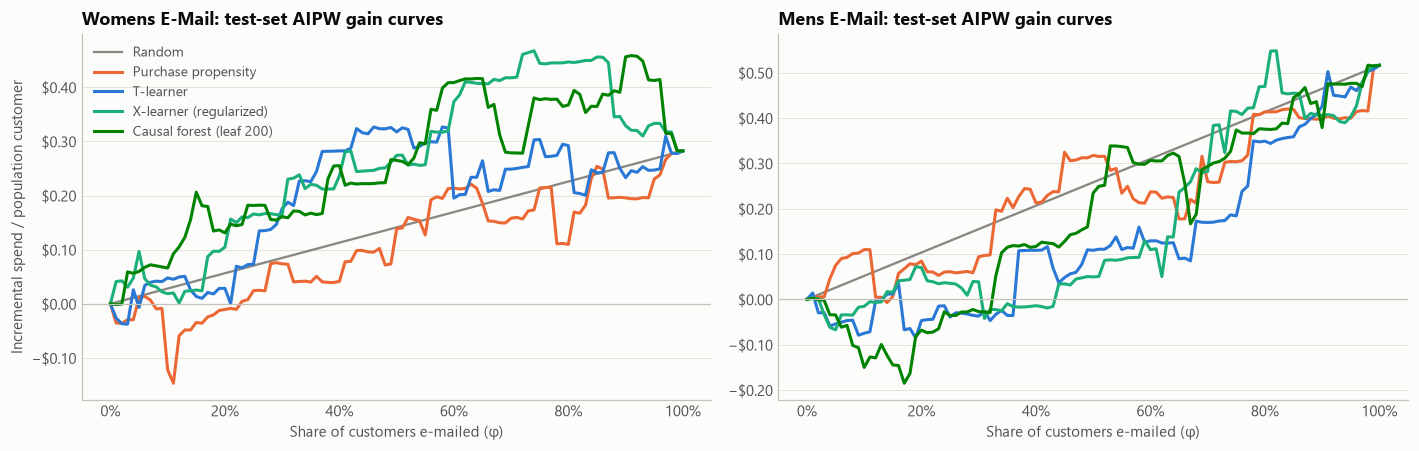

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
curves = []
for ax, key in zip(axes, config.CAMPAIGNS):
    g = G["spend"][key].to_numpy()
    ax.plot([0, 1], [0, g.mean()], color=P.MUTED, lw=1.5, label="Random")
    curves.append(pd.DataFrame({"campaign": key, "policy": "Random", "coverage": evaluation.GRID,
                                "gain": evaluation.GRID * g.mean()}))
    for name in POLICIES:
        c = evaluation.gain_curve(test_scores[key][name].to_numpy(), g)
        curves.append(pd.DataFrame({"campaign": key, "policy": name, "coverage": evaluation.GRID, "gain": c}))
        ax.plot(evaluation.GRID, c, color=P.color_for(name), lw=2, label=name)
    ax.axhline(0, color=P.AXIS, lw=0.8)
    P.percent(ax, "x"); P.dollar(ax)
    ax.set_title(f"{config.CAMPAIGNS[key]}: test-set AIPW gain curves")
    ax.set_xlabel("Share of customers e-mailed (φ)")
axes[0].set_ylabel("Incremental spend / population customer"); axes[0].legend(loc="upper left")
fig.tight_layout(); P.savefig(fig, "04_test_gain_curves"); plt.show()
curves = pd.concat(curves, ignore_index=True)

## 3 · Policy evaluation under the default budget

Every policy gets the same \$3,000 per 100k customers.

* **Random** and **ranking** policies (purchase propensity) spend the whole budget on the campaign with the larger *development-set* ATE, because a ranking cannot tell whether a contact pays for itself.
* **Uplift** policies use their dollar CATEs. They contact a customer only if $m\hat\tau - c > 0$, and may therefore spend *less* than the budget.

All values are **held-out policy-value estimates** (AIPW on test data), expressed per 100,000 customers, with 95% CIs.

In [5]:
frame = pd.DataFrame(index=X.index[test])
for key in scenario.ARM_ORDER:
    for name in POLICIES:
        frame[f"{name}|{key}"] = test_scores[key][name]
    for o in ["spend", "visit"]:
        frame[f"gamma_{o}|{key}"] = G[o][key]
meta = {"ranking_models": ["Purchase propensity"], "uplift_models": ["T-learner", CHALLENGER, SELECTED],
        "selected_model": SELECTED, "challenger_model": CHALLENGER, "dev_ate_spend": dev_ate}

results = {opt_key: scenario.run_scenario(frame, meta, opt_key, M, C, B, POP) for opt_key in scenario.CAMPAIGN_OPTIONS}
show_cols = ["coverage", "mens_share", "spend_on_email", "inc_spend", "profit", "profit_ci_low", "profit_ci_high", "roi"]
pd.concat({scenario.CAMPAIGN_OPTIONS[k]: v[show_cols] for k, v in results.items()}, names=["campaign option"]).style.format({
    "coverage": "{:.0%}", "mens_share": "{:.0%}", "spend_on_email": P.money0, "inc_spend": P.money0,
    "profit": P.money0, "profit_ci_low": P.money0, "profit_ci_high": P.money0, "roi": "{:.2f}"})

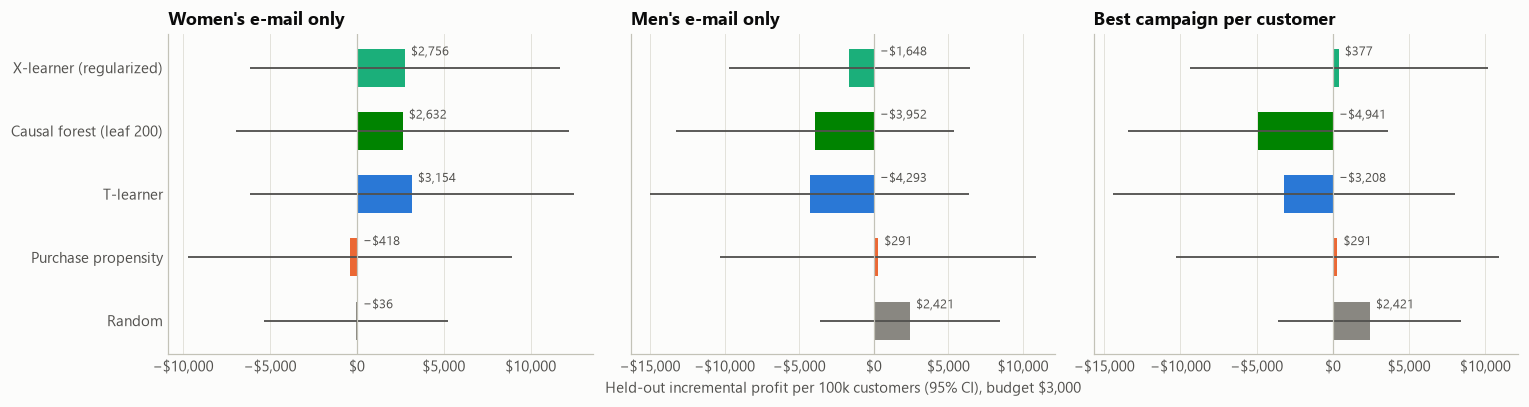

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
order = ["Random", "Purchase propensity", "T-learner", CHALLENGER, SELECTED]
for ax, (k, r) in zip(axes, results.items()):
    r = r.loc[order]
    y = np.arange(len(r))
    ax.barh(y, r.profit, color=[P.color_for(p) for p in r.index], height=0.6)
    ax.hlines(y, r.profit_ci_low, r.profit_ci_high, color=P.INK_2, lw=1.2)
    ax.axvline(0, color=P.AXIS, lw=0.8)
    for yi, v in zip(y, r.profit):
        ax.annotate(P.money0(v), (max(v, 0), yi), xytext=(4, 8), textcoords="offset points", fontsize=8.5, color=P.INK_2)
    ax.set_yticks(y, r.index); ax.grid(axis="y", visible=False); ax.grid(axis="x")
    ax.set_title(scenario.CAMPAIGN_OPTIONS[k]); P.dollar(ax, "x", 0)
axes[1].set_xlabel("Held-out incremental profit per 100k customers (95% CI), budget $3,000")
fig.tight_layout(); P.savefig(fig, "04_policy_profit_default"); plt.show()

### 3b · Paired comparisons
The intervals above are for each policy on its own. Policies are evaluated on the **same** test customers, so their difference has a much tighter **paired** interval.

In [7]:
gamma_m = scenario.gamma_matrix(frame)
def assignment(name, option, budget=B):
    if name == "Random":
        return None
    if name in meta["ranking_models"]:
        return scenario.ranking_policy(frame, name, option, C, budget, POP, dev_ate)
    return scenario.uplift_policy(frame, name, option, M, C, budget, POP)

pairs = [(SELECTED, "best", "Purchase propensity", "womens"), (SELECTED, "best", "Purchase propensity", "best"),
         (SELECTED, "best", SELECTED, "womens"), (SELECTED, "best", CHALLENGER, "best"),
         (SELECTED, "womens", "Purchase propensity", "womens"), (SELECTED, "best", "T-learner", "best")]
rows = []
for a, oa, b, ob in pairs:
    d = opt.compare_allocations(assignment(a, oa), assignment(b, ob), gamma_m, M, C)
    rows.append({"A": f"{a} [{oa}]", "B": f"{b} [{ob}]", "profit A − B per 100k": d["estimate"] * POP,
                 "ci_low": d["ci_low"] * POP, "ci_high": d["ci_high"] * POP, "z": d["estimate"] / d["se"]})
# Random: analytic expectation, paired with the selected policy
cov_cap = min(1.0, B / (C * POP))
arm_r = int(np.argmax([dev_ate[a] for a in scenario.ARM_ORDER]))
z_sel = opt.profit_contributions(assignment(SELECTED, "best"), gamma_m, M, C)
z_rnd = cov_cap * (M * gamma_m[:, arm_r] - C)
d = evaluation.mean_ci(z_sel - z_rnd)
rows.append({"A": f"{SELECTED} [best]", "B": "Random [larger-ATE campaign]", "profit A − B per 100k": d["estimate"] * POP,
             "ci_low": d["ci_low"] * POP, "ci_high": d["ci_high"] * POP, "z": d["estimate"] / d["se"]})
paired = pd.DataFrame(rows).set_index(["A", "B"])
paired.style.format({"profit A − B per 100k": P.money0, "ci_low": P.money0, "ci_high": P.money0, "z": "{:.2f}"})

### 3c · Estimator cross-check: IPW vs AIPW
Under randomization, a plain inverse-propensity estimate of the same policy should agree with AIPW within noise.

In [8]:
a_sel = assignment(SELECTED, "best")
arm = df.loc[test, "segment"].to_numpy()
y = df.loc[test, "spend"].to_numpy()
shares = data.arm_shares(df)
ipw = np.column_stack([evaluation.ipw_scores(arm, y, config.CAMPAIGNS[k], config.CONTROL, shares) for k in scenario.ARM_ORDER])
cmp = pd.DataFrame({"AIPW": opt.evaluate_allocation(a_sel, gamma_m, M, C), "IPW": opt.evaluate_allocation(a_sel, ipw, M, C)}).T
(cmp[["profit", "profit_ci_low", "profit_ci_high"]] * POP).style.format(P.money0)

,profit,profit_ci_low,profit_ci_high
AIPW,$377,"−$9,391","$10,146"
IPW,−$101,"−$9,884","$9,681"


## 4 · How many customers should be e-mailed?

The cells below remove the budget and trace held-out profit as coverage grows, for each ranking. The dot marks the coverage that each **uplift** model chooses on its own by contacting only customers with $m\hat\tau > c$. That break-even rule is the decision a ranking alone cannot make.

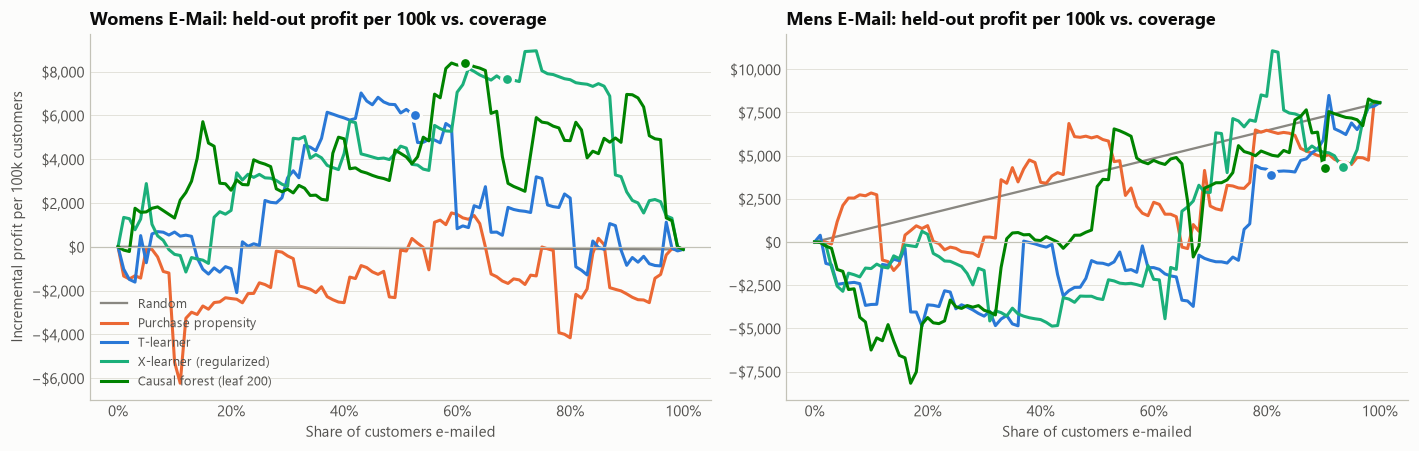

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, key in zip(axes, config.CAMPAIGNS):
    g = G["spend"][key].to_numpy()
    ax.plot([0, 1], [0, (M * g.mean() - C) * POP], color=P.MUTED, lw=1.5, label="Random")
    for name in POLICIES:
        prof = (M * evaluation.gain_curve(test_scores[key][name].to_numpy(), g) - C * evaluation.GRID) * POP
        ax.plot(evaluation.GRID, prof, color=P.color_for(name), lw=2, label=name)
        if name != "Purchase propensity":
            a = scenario.uplift_policy(frame, name, key, M, C, None, POP)
            r = opt.evaluate_allocation(a, gamma_m, M, C)
            ax.scatter([r["coverage"]], [r["profit"] * POP], color=P.color_for(name), s=60, zorder=4,
                       edgecolor=P.SURFACE, linewidth=2)
    ax.axhline(0, color=P.AXIS, lw=0.8)
    P.percent(ax, "x"); P.dollar(ax, "y", 0)
    ax.set_xlabel("Share of customers e-mailed")
    ax.set_title(f"{config.CAMPAIGNS[key]}: held-out profit per 100k vs. coverage")
axes[0].set_ylabel("Incremental profit per 100k customers"); axes[0].legend(loc="lower left", fontsize=8.5)
fig.tight_layout(); P.savefig(fig, "04_profit_vs_coverage"); plt.show()

### 4b · Is the break-even rule worth it? (no budget limit, paired)
Each uplift policy's own coverage choice is compared with (i) e-mailing everyone with that campaign and (ii) propensity targeting at the *same* coverage, so the only difference is *who* is chosen.

In [10]:
rows = []
for option in scenario.CAMPAIGN_OPTIONS:
    ta_arm = scenario.ARM_ORDER.index(option) if option != "best" else int(np.argmax([dev_ate[a] for a in scenario.ARM_ORDER]))
    a_all = np.full(len(frame), ta_arm)
    r_all = opt.evaluate_allocation(a_all, gamma_m, M, C)
    rows.append({"option": scenario.CAMPAIGN_OPTIONS[option], "policy": "Treat all", "coverage": 1.0,
                 "profit per 100k": r_all["profit"] * POP})
    for name in ["T-learner", CHALLENGER, SELECTED]:
        a = scenario.uplift_policy(frame, name, option, M, C, None, POP)
        r = opt.evaluate_allocation(a, gamma_m, M, C)
        d_all = opt.compare_allocations(a, a_all, gamma_m, M, C)
        b = scenario.ranking_policy(frame, "Purchase propensity", option, C, None, POP, dev_ate, coverage=r["coverage"])
        d_p = opt.compare_allocations(a, b, gamma_m, M, C)
        rows.append({"option": scenario.CAMPAIGN_OPTIONS[option], "policy": name, "coverage": r["coverage"],
                     "profit per 100k": r["profit"] * POP,
                     "vs treat all": d_all["estimate"] * POP, "vs treat all CI": f"{P.money0(d_all['ci_low'] * POP)} to {P.money0(d_all['ci_high'] * POP)}",
                     "vs propensity @ same coverage": d_p["estimate"] * POP,
                     "vs propensity CI": f"{P.money0(d_p['ci_low'] * POP)} to {P.money0(d_p['ci_high'] * POP)}"})
nobudget = pd.DataFrame(rows).set_index(["option", "policy"])
nobudget.to_csv(config.ARTIFACTS_DIR / "test_no_budget.csv")
nobudget.style.format({"coverage": "{:.0%}", "profit per 100k": P.money0, "vs treat all": P.money0,
                       "vs propensity @ same coverage": P.money0}, na_rep="—")

## 5 · Budget scenarios

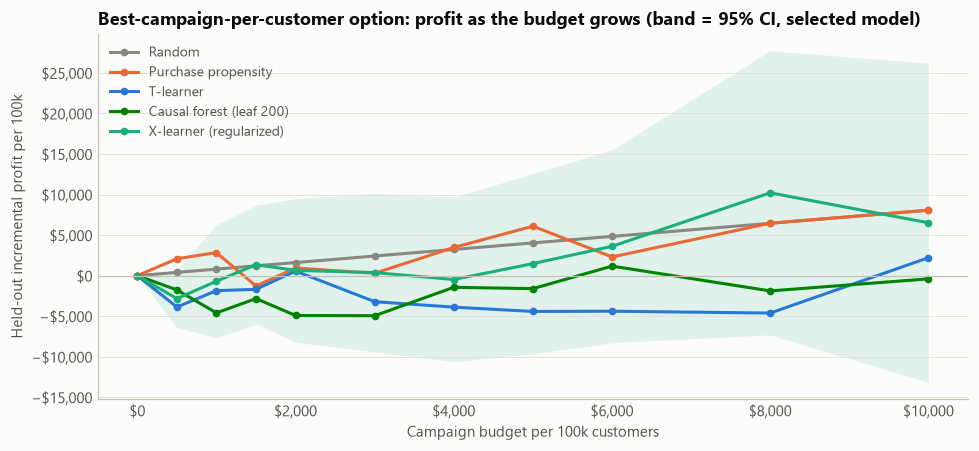

policy,Random,Purchase propensity,T-learner,Causal forest (leaf 200),X-learner (regularized)
budget,,,,,
$0,$0,$0,$0,$0,$0
$500,$404,"$2,089","−$3,870","−$1,757","−$2,833"
"$1,000",$807,"$2,840","−$1,851","−$4,590",−$688
"$1,500","$1,211","−$1,279","−$1,686","−$2,831","$1,349"
"$2,000","$1,614",$947,$569,"−$4,910",$649
"$3,000","$2,421",$291,"−$3,208","−$4,941",$377
"$4,000","$3,228","$3,474","−$3,882","−$1,437",−$478
"$5,000","$4,035","$6,100","−$4,415","−$1,602","$1,484"
"$6,000","$4,842","$2,304","−$4,386","$1,176","$3,619"


In [11]:
budgets = np.array([0, 500, 1000, 1500, 2000, 3000, 4000, 5000, 6000, 8000, 10000], float)
bc = scenario.budget_curve(frame, meta, "best", M, C, budgets, POP)
fig, ax = plt.subplots(figsize=(9, 4.2))
for name in ["Random", "Purchase propensity", "T-learner", CHALLENGER, SELECTED]:
    s = bc[bc.policy == name]
    ax.plot(s.budget, s.profit, color=P.color_for(name), lw=2, marker="o", ms=4, label=name)
    if name == SELECTED:
        ax.fill_between(s.budget, s.profit_ci_low, s.profit_ci_high, color=P.color_for(name), alpha=0.12, lw=0)
ax.axhline(0, color=P.AXIS, lw=0.8)
P.dollar(ax, "x", 0); P.dollar(ax, "y", 0)
ax.set_xlabel("Campaign budget per 100k customers"); ax.set_ylabel("Held-out incremental profit per 100k")
ax.set_title("Best-campaign-per-customer option: profit as the budget grows (band = 95% CI, selected model)")
ax.legend(loc="upper left")
fig.tight_layout(); P.savefig(fig, "04_budget_curve"); plt.show()
bc.pivot(index="budget", columns="policy", values="profit")[["Random", "Purchase propensity", "T-learner", CHALLENGER, SELECTED]].style.format(
    P.money0).format_index(P.money0)

## 6 · Sensitivity to the economic assumptions

The economics are **assumptions**, so the recommendation should be robust to them. The heatmaps vary the margin and the cost per e-mail at the default budget, using the best-campaign option:
* **left:** held-out profit of the selected policy;
* **right:** its paired advantage over purchase-propensity targeting.

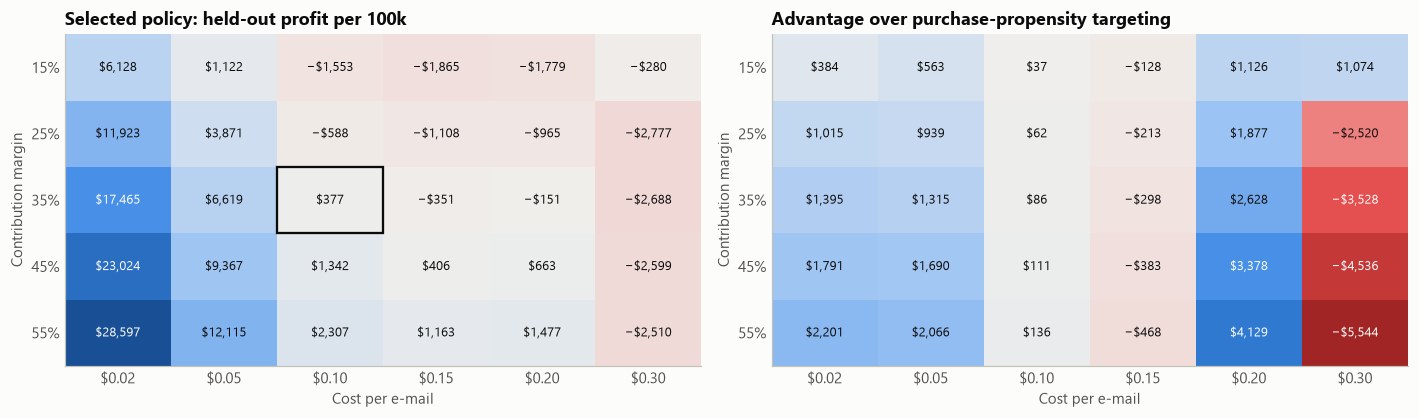

In [12]:
margins = [0.15, 0.25, 0.35, 0.45, 0.55]
costs = [0.02, 0.05, 0.10, 0.15, 0.20, 0.30]
prof = np.zeros((len(margins), len(costs))); adv = np.zeros_like(prof)
for i, m in enumerate(margins):
    for j, c in enumerate(costs):
        a = scenario.uplift_policy(frame, SELECTED, "best", m, c, B, POP)
        b = scenario.ranking_policy(frame, "Purchase propensity", "best", c, B, POP, dev_ate)
        prof[i, j] = opt.evaluate_allocation(a, gamma_m, m, c)["profit"] * POP
        adv[i, j] = opt.compare_allocations(a, b, gamma_m, m, c)["estimate"] * POP
sens = pd.DataFrame(adv, index=margins, columns=costs)

from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
div = LinearSegmentedColormap.from_list("div", P.DIVERGING[::-1])
fig, axes = plt.subplots(1, 2, figsize=(13, 3.9))
for ax, mat, title in [(axes[0], prof, "Selected policy: held-out profit per 100k"),
                       (axes[1], adv, "Advantage over purchase-propensity targeting")]:
    lim = np.abs(mat).max()
    im = ax.imshow(mat, cmap=div, norm=TwoSlopeNorm(0, -lim, lim), aspect="auto")
    for i in range(len(margins)):
        for j in range(len(costs)):
            ax.text(j, i, P.money0(mat[i, j]), ha="center", va="center", fontsize=8.5,
                    color="white" if abs(mat[i, j]) > 0.6 * lim else P.INK)
    ax.set_xticks(range(len(costs)), [f"${c:.2f}" for c in costs]); ax.set_yticks(range(len(margins)), [f"{m:.0%}" for m in margins])
    ax.set_xlabel("Cost per e-mail"); ax.set_ylabel("Contribution margin"); ax.grid(False); ax.set_title(title)
    if ax is axes[0]:
        ax.add_patch(plt.Rectangle((costs.index(C) - .5, margins.index(M) - .5), 1, 1, fill=False, ec=P.INK, lw=1.5))
fig.tight_layout(); P.savefig(fig, "04_sensitivity_heatmaps"); plt.show()

## 7 · Optimality check: greedy vs. exact MILP

In [13]:
tau = scenario.score_matrix(frame, SELECTED)
net = opt.net_value(tau, M, C)
cap = scenario.contacts_cap(B, C, len(frame), POP)
t0 = time.time(); a_greedy = opt.allocate(net, C, cap); tg = time.time() - t0
t0 = time.time(); a_milp = opt.solve_milp(net, C, cap); tm = time.time() - t0
val = lambda a: net[np.arange(len(a))[a >= 0], a[a >= 0]].sum()
print(f"Greedy objective {val(a_greedy):.4f} ({tg * 1000:.0f} ms) | MILP objective {val(a_milp):.4f} ({tm:.1f} s)")
print(f"Budget used: greedy {(a_greedy >= 0).sum() * C:.2f} / MILP {(a_milp >= 0).sum() * C:.2f} / cap {cap:.2f}")
assert np.isclose(val(a_greedy), val(a_milp), rtol=1e-6)

Greedy objective 1562.9110 (7 ms) | MILP objective 1562.9110 (13.3 s)
Budget used: greedy 384.00 / MILP 384.00 / cap 384.00


## 8 · Who gets which e-mail?

In [14]:
a = scenario.uplift_policy(frame, SELECTED, "best", M, C, B, POP)
who = df.loc[test, ["mens", "womens", "newbie", "channel"]].copy()
who["merch_history"] = np.select([(who.mens == 1) & (who.womens == 1), who.mens == 1, who.womens == 1],
                                 ["both", "mens only", "womens only"], "neither")
who["decision"] = np.select([a == 0, a == 1], ["Men's e-mail", "Women's e-mail"], "No e-mail")
pd.crosstab(who["merch_history"], who["decision"], normalize="index").style.format("{:.0%}").set_caption(
    f"{SELECTED}, best campaign per customer, default economics")

decision,Men's e-mail,No e-mail,Women's e-mail
merch_history,,,
both,45%,43%,12%
mens only,24%,67%,8%
womens only,13%,79%,8%


## 9 · Export the frozen test-set artifacts for the dashboard

In [15]:
seg_cols = df.loc[test, ["recency", "history", "history_segment", "mens", "womens", "zip_code", "newbie", "channel"]].copy()
seg_cols["merch_history"] = who["merch_history"]
seg_cols["recency_bucket"] = pd.cut(seg_cols.recency, [0, 3, 6, 9, 12], labels=["1-3 mo", "4-6 mo", "7-9 mo", "10-12 mo"]).astype(str)
seg_cols["customer_type"] = seg_cols.newbie.map({1: "new", 0: "existing"})
export = seg_cols.join(frame)
export.to_csv(config.ARTIFACTS_DIR / "test_scores.csv")
curves.to_csv(config.ARTIFACTS_DIR / "test_gain_curves.csv", index=False)
rank_test.to_csv(config.ARTIFACTS_DIR / "test_ranking_metrics.csv")
meta.update({"n_test": int(test.sum()), "margin": M, "cost": C, "budget": B, "population": POP,
             "seed": config.SEED, "test_ate_spend": ate_test.to_dict()})
with open(config.ARTIFACTS_DIR / "test_metadata.json", "w") as f:
    json.dump(meta, f, indent=2)
results_flat = pd.concat({k: v for k, v in results.items()}, names=["option"]).reset_index()
results_flat.to_csv(config.ARTIFACTS_DIR / "test_policy_results.csv", index=False)
paired.reset_index().to_csv(config.ARTIFACTS_DIR / "test_paired_comparisons.csv", index=False)
print("exported:", [p.name for p in sorted(config.ARTIFACTS_DIR.glob("test_*"))])

exported: ['test_gain_curves.csv', 'test_metadata.json', 'test_no_budget.csv', 'test_paired_comparisons.csv', 'test_policy_results.csv', 'test_ranking_metrics.csv', 'test_scores.csv']


## 10 · Findings

In [16]:
rb, rw = results["best"], results["womens"]
p = paired.reset_index()
def row(a, b):
    r = p[(p.A == a) & (p.B == b)].iloc[0]
    return f"{P.money0(r['profit A − B per 100k'])} (95% CI {P.money0(r.ci_low)} to {P.money0(r.ci_high)})"
display(P.md(f"""
**Default scenario:** \$3,000 budget per 100k customers, 35% margin, \$0.10 per e-mail. All numbers are held-out AIPW estimates on 12,800 test customers.

| Policy | Coverage | Profit per 100k (95% CI) |
|---|---|---|
| Random, Men's e-mail | {rb.loc['Random','coverage']:.0%} | {P.money0(rb.loc['Random','profit'])} ({P.money0(rb.loc['Random','profit_ci_low'])} to {P.money0(rb.loc['Random','profit_ci_high'])}) |
| Purchase propensity, Men's e-mail | {rb.loc['Purchase propensity','coverage']:.0%} | {P.money0(rb.loc['Purchase propensity','profit'])} ({P.money0(rb.loc['Purchase propensity','profit_ci_low'])} to {P.money0(rb.loc['Purchase propensity','profit_ci_high'])}) |
| Purchase propensity, Women's e-mail | {rw.loc['Purchase propensity','coverage']:.0%} | {P.money0(rw.loc['Purchase propensity','profit'])} ({P.money0(rw.loc['Purchase propensity','profit_ci_low'])} to {P.money0(rw.loc['Purchase propensity','profit_ci_high'])}) |
| **{SELECTED}, best campaign per customer** | {rb.loc[SELECTED,'coverage']:.0%} | **{P.money0(rb.loc[SELECTED,'profit'])}** ({P.money0(rb.loc[SELECTED,'profit_ci_low'])} to {P.money0(rb.loc[SELECTED,'profit_ci_high'])}) |
| {CHALLENGER}, best campaign per customer | {rb.loc[CHALLENGER,'coverage']:.0%} | {P.money0(rb.loc[CHALLENGER,'profit'])} ({P.money0(rb.loc[CHALLENGER,'profit_ci_low'])} to {P.money0(rb.loc[CHALLENGER,'profit_ci_high'])}) |

**Paired differences** (same test customers):
* {SELECTED} [best] − Random: {row(f'{SELECTED} [best]', 'Random [larger-ATE campaign]')}
* {SELECTED} [best] − Purchase propensity [best]: {row(f'{SELECTED} [best]', 'Purchase propensity [best]')}
* {SELECTED} [best] − {CHALLENGER} [best]: {row(f'{SELECTED} [best]', f'{CHALLENGER} [best]')}
* {SELECTED} [best] − {SELECTED} [Women's only]: {row(f'{SELECTED} [best]', f'{SELECTED} [womens]')}
"""))


**Default scenario:** \$3,000 budget per 100k customers, 35% margin, \$0.10 per e-mail. All numbers are held-out AIPW estimates on 12,800 test customers.

| Policy | Coverage | Profit per 100k (95% CI) |
|---|---|---|
| Random, Men's e-mail | 30% | \$2,421 (−\$3,594 to \$8,436) |
| Purchase propensity, Men's e-mail | 30% | \$291 (−\$10,295 to \$10,877) |
| Purchase propensity, Women's e-mail | 30% | −\$418 (−\$9,739 to \$8,904) |
| **X-learner (regularized), best campaign per customer** | 30% | **\$377** (−\$9,391 to \$10,146) |
| Causal forest (leaf 200), best campaign per customer | 30% | −\$4,941 (−\$13,467 to \$3,585) |

**Paired differences** (same test customers):
* X-learner (regularized) [best] − Random: −\$2,044 (95% CI −\$11,374 to \$7,287)
* X-learner (regularized) [best] − Purchase propensity [best]: \$86 (95% CI −\$11,553 to \$11,726)
* X-learner (regularized) [best] − Causal forest (leaf 200) [best]: \$5,318 (95% CI −\$1,843 to \$12,480)
* X-learner (regularized) [best] − X-learner (regularized) [Women's only]: −\$2,379 (95% CI −\$11,532 to \$6,774)


### Interpretation

**1 · On one 12,800-customer test set, no policy comparison is statistically decisive.** Every profit interval at the \$3k budget spans roughly ±\$10k per 100k customers, while the differences between policies are a few thousand dollars. This is the power problem flagged in notebook 01 (spend MDE ≈ 2× the Women's ATE on a 20% split) showing up in decision form. Notebook 06 pools evidence across splits.

**2 · The Women's e-mail, the pre-registered primary arm, replicates the development findings.**
* On the test set, the regularized X-learner and causal forest rank Women's uplift clearly better than purchase propensity (AUGC ≈ +0.12 vs −0.04). Their dollar predictions are well calibrated out of sample (BLP slopes 0.81 / 0.93).
* With no budget cap, the uplift models' own break-even rule chooses to e-mail 53–69% of customers, earning about \$6–8k per 100k. E-mailing everyone earns about \$0, because the Women's effect on this test set barely covers the \$0.10 cost. Propensity targeting at the same coverage earns between about −\$1.7k and +\$1.2k. The point estimates consistently favour uplift targeting, but each paired interval still includes zero.
* **This is where uplift modelling earns its keep:** deciding *whether* each contact pays for itself, which a propensity ranking cannot do.

**3 · The Men's e-mail does not replicate any targeting gain.** Every model is at or below random on the test set (BLP slopes < 0), consistent with the null heterogeneity test in notebook 01. For a campaign whose effect is positive and roughly uniform, the profit-maximizing decision is to **e-mail broadly**. Uplift models that chase noise give money away: on Men's, every uplift policy earns less than treat-all.

**4 · The "best campaign per customer" policy inherits the Men's noise.** It needs a reliable comparison of two CATEs per customer. One of them carries no signal, so at the default budget it is no better than random Men's mailing. Per-customer campaign choice is only as good as the *worse* of the two effect models.

**5 · Mechanics are sound.** The greedy allocation matches the exact MILP optimum. IPW and AIPW agree within noise. The selected policy never exceeds the budget.